# 🐾 Will this animal be adopted?
### Predicting adoptions at the Austin Animal Center

**Goal:** predict, on the day an animal arrives at the shelter, whether it will be adopted (binary classification).

**Data:** [Austin Animal Center Shelter Intakes and Outcomes (Kaggle)](https://www.kaggle.com/aaronschlegel/austin-animal-center-shelter-intakes-and-outcomes) – `aac_intakes_outcomes.csv`

## 1. Data exploration

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV, RandomizedSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.inspection import permutation_importance

from model_utils import evaluate_model, results_table

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

In [2]:
df = pd.read_csv("aac_intakes_outcomes.csv")
print(df.shape)
df.head()

(79672, 41)


,age_upon_outcome,animal_id_outcome,date_of_birth,outcome_subtype,outcome_type,sex_upon_outcome,age_upon_outcome_(days),age_upon_outcome_(years),age_upon_outcome_age_group,outcome_datetime,outcome_month,outcome_year,outcome_monthyear,outcome_weekday,outcome_hour,outcome_number,dob_year,dob_month,dob_monthyear,age_upon_intake,animal_id_intake,animal_type,breed,color,found_location,intake_condition,intake_type,sex_upon_intake,count,age_upon_intake_(days),age_upon_intake_(years),age_upon_intake_age_group,intake_datetime,intake_month,intake_year,intake_monthyear,intake_weekday,intake_hour,intake_number,time_in_shelter,time_in_shelter_days
0,10 years,A006100,2007-07-09 00:00:00,NaN,Return to Owner,Neutered Male,3650,10.0,"(7.5, 10.0]",2017-12-07 14:07:00,12,2017,2017-12,Thursday,0,1.0,2007,7,2017-12,10 years,A006100,Dog,Spinone Italiano Mix,Yellow/White,Colony Creek And Hunters Trace in Austin (TX),Normal,Stray,Neutered Male,1,3650,10.0,"(7.5, 10.0]",2017-12-07 00:00:00,12,2017,2017-12,Thursday,14,1.0,0 days 14:07:00.000000000,0.588194
1,7 years,A006100,2007-07-09 00:00:00,NaN,Return to Owner,Neutered Male,2555,7.0,"(5.0, 7.5]",2014-12-20 16:35:00,12,2014,2014-12,Saturday,16,2.0,2007,7,2014-12,7 years,A006100,Dog,Spinone Italiano Mix,Yellow/White,8700 Research Blvd in Austin (TX),Normal,Public Assist,Neutered Male,1,2555,7.0,"(5.0, 7.5]",2014-12-19 10:21:00,12,2014,2014-12,Friday,10,2.0,1 days 06:14:00.000000000,1.259722
2,6 years,A006100,2007-07-09 00:00:00,NaN,Return to Owner,Neutered Male,2190,6.0,"(5.0, 7.5]",2014-03-08 17:10:00,3,2014,2014-03,Saturday,17,3.0,2007,7,2014-03,6 years,A006100,Dog,Spinone Italiano Mix,Yellow/White,8700 Research in Austin (TX),Normal,Public Assist,Neutered Male,1,2190,6.0,"(5.0, 7.5]",2014-03-07 14:26:00,3,2014,2014-03,Friday,14,3.0,1 days 02:44:00.000000000,1.113889
3,10 years,A047759,2004-04-02 00:00:00,Partner,Transfer,Neutered Male,3650,10.0,"(7.5, 10.0]",2014-04-07 15:12:00,4,2014,2014-04,Monday,15,1.0,2004,4,2014-04,10 years,A047759,Dog,Dachshund,Tricolor,Austin (TX),Normal,Owner Surrender,Neutered Male,1,3650,10.0,"(7.5, 10.0]",2014-04-02 15:55:00,4,2014,2014-04,Wednesday,15,1.0,4 days 23:17:00.000000000,4.970139
4,16 years,A134067,1997-10-16 00:00:00,NaN,Return to Owner,Neutered Male,5840,16.0,"(15.0, 17.5]",2013-11-16 11:54:00,11,2013,2013-11,Saturday,11,1.0,1997,10,2013-11,16 years,A134067,Dog,Shetland Sheepdog,Brown/White,12034 Research Blvd in Austin (TX),Injured,Public Assist,Neutered Male,1,5840,16.0,"(15.0, 17.5]",2013-11-16 09:02:00,11,2013,2013-11,Saturday,9,1.0,0 days 02:52:00.000000000,0.119444


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 79672 entries, 0 to 79671
Data columns (total 41 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   age_upon_outcome            79672 non-null  str    
 1   animal_id_outcome           79672 non-null  str    
 2   date_of_birth               79672 non-null  str    
 3   outcome_subtype             36348 non-null  str    
 4   outcome_type                79662 non-null  str    
 5   sex_upon_outcome            79671 non-null  str    
 6   age_upon_outcome_(days)     79672 non-null  int64  
 7   age_upon_outcome_(years)    79672 non-null  float64
 8   age_upon_outcome_age_group  79672 non-null  str    
 9   outcome_datetime            79672 non-null  str    
 10  outcome_month               79672 non-null  int64  
 11  outcome_year                79672 non-null  int64  
 12  outcome_monthyear           79672 non-null  str    
 13  outcome_weekday             79672 non-null

In [4]:
missing = df.isna().sum()
print(missing[missing > 0].sort_values(ascending=False))
print("Duplicate rows:", df.duplicated().sum())

outcome_subtype     43324
outcome_type           10
sex_upon_outcome        1
sex_upon_intake         1
dtype: int64
Duplicate rows: 35


### Target: `adopted`

In [5]:
df["outcome_type"].value_counts()

outcome_type
Adoption           33594
Transfer           23799
Return to Owner    14791
Euthanasia          6244
Died                 690
Disposal             304
Rto-Adopt            179
Missing               46
Relocate              15
Name: count, dtype: int64

adopted
0    0.578
1    0.422
Name: proportion, dtype: float64


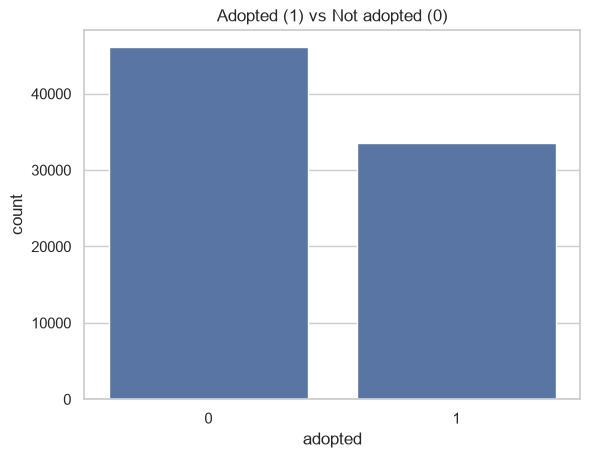

In [6]:
df["adopted"] = (df["outcome_type"] == "Adoption").astype(int)

print(df["adopted"].value_counts(normalize=True).round(3))
sns.countplot(data=df, x="adopted")
plt.title("Adopted (1) vs Not adopted (0)")
plt.show()

### Adoption rate by group

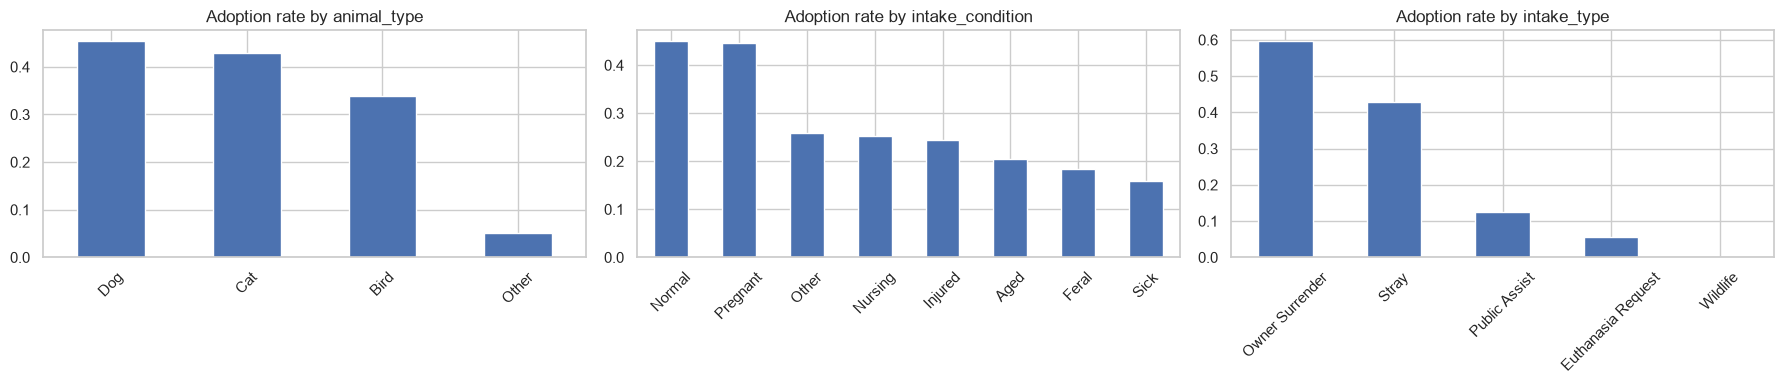

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4))
for ax, col in zip(axes, ["animal_type", "intake_condition", "intake_type"]):
    df.groupby(col)["adopted"].mean().sort_values(ascending=False).plot(kind="bar", ax=ax)
    ax.set_title(f"Adoption rate by {col}")
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()

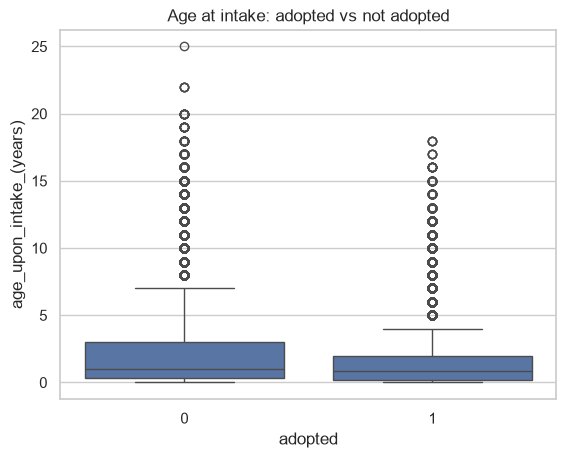

Breeds: 2155 | Colors: 529


In [8]:
sns.boxplot(data=df, x="adopted", y="age_upon_intake_(years)")
plt.title("Age at intake: adopted vs not adopted")
plt.show()

print("Breeds:", df["breed"].nunique(), "| Colors:", df["color"].nunique())

### Feature selection
Only information available **at intake** is used. Outcome columns (`outcome_subtype`, `time_in_shelter`, outcome dates…) would leak the answer.

In [9]:
features = [
    "animal_type", "age_upon_intake_(years)", "sex_upon_intake", "breed",
    "color", "intake_type", "intake_condition", "intake_month",
]
df_model = df[features + ["adopted"]].copy()
df_model.shape

(79672, 9)

## 2. Data preparation and feature engineering

In [10]:
# Duplicates are kept: with few columns, different animals can share the same profile
df_model = df_model.dropna()
df_model = df_model[df_model["age_upon_intake_(years)"] >= 0]
df_model.shape

(79671, 9)

In [11]:
# Sex and sterilization
df_model["is_male"] = df_model["sex_upon_intake"].isin(["Neutered Male", "Intact Male"]).astype(int)
df_model["is_sterilized"] = df_model["sex_upon_intake"].str.contains("Neutered|Spayed").astype(int)
df_model["sex_unknown"] = (df_model["sex_upon_intake"] == "Unknown").astype(int)

# Breed: mixed flag + top 10 main breeds
df_model["is_mix"] = df_model["breed"].str.contains("Mix|/").astype(int)
df_model["main_breed"] = df_model["breed"].str.replace(" Mix", "", regex=False).str.split("/").str[0].str.strip()
top_breeds = df_model["main_breed"].value_counts().head(10).index
df_model["main_breed"] = df_model["main_breed"].where(df_model["main_breed"].isin(top_breeds), "Other")

# Color: multicolor flag + top 10 main colors
df_model["is_multicolor"] = df_model["color"].str.contains("/").astype(int)
df_model["main_color"] = df_model["color"].str.split("/").str[0].str.split(" ").str[0]
top_colors = df_model["main_color"].value_counts().head(10).index
df_model["main_color"] = df_model["main_color"].where(df_model["main_color"].isin(top_colors), "Other")

# Age and season
df_model["is_baby"] = (df_model["age_upon_intake_(years)"] < 1).astype(int)
seasons = {12: "Winter", 1: "Winter", 2: "Winter", 3: "Spring", 4: "Spring", 5: "Spring",
           6: "Summer", 7: "Summer", 8: "Summer", 9: "Autumn", 10: "Autumn", 11: "Autumn"}
df_model["intake_season"] = df_model["intake_month"].map(seasons)

df_model = df_model.drop(columns=["sex_upon_intake", "breed", "color", "intake_month"])
df_model.head()

,animal_type,age_upon_intake_(years),intake_type,intake_condition,adopted,is_male,is_sterilized,sex_unknown,is_mix,main_breed,is_multicolor,main_color,is_baby,intake_season
0,Dog,10.0,Stray,Normal,0,1,1,0,1,Other,1,Other,0,Winter
1,Dog,7.0,Public Assist,Normal,0,1,1,0,1,Other,1,Other,0,Winter
2,Dog,6.0,Public Assist,Normal,0,1,1,0,1,Other,1,Other,0,Spring
3,Dog,10.0,Owner Surrender,Normal,0,1,1,0,0,Dachshund,0,Tricolor,0,Spring
4,Dog,16.0,Public Assist,Injured,0,1,1,0,0,Other,1,Brown,0,Autumn


In [12]:
for feature in ["is_male", "is_sterilized", "is_mix", "is_multicolor", "is_baby"]:
    print(feature, df_model.groupby(feature)["adopted"].mean().round(2).to_dict())

is_male {0: 0.4, 1: 0.44}
is_sterilized {0: 0.44, 1: 0.38}
is_mix {0: 0.27, 1: 0.43}
is_multicolor {0: 0.4, 1: 0.44}
is_baby {0: 0.36, 1: 0.51}


In [13]:
text_columns = df_model.select_dtypes(include=["object", "string"]).columns
df_encoded = pd.get_dummies(df_model, columns=text_columns, drop_first=True, dtype=int)

print(df_encoded.shape)
print("Missing values:", df_encoded.isna().sum().sum())

(79671, 45)
Missing values: 0


## 3. Baseline and first models

In [14]:
X = df_encoded.drop(columns="adopted")
y = df_encoded["adopted"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Scaler fitted on train only to avoid leakage
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Train:", X_train.shape, "| Test:", X_test.shape)

Train: (63736, 44) | Test: (15935, 44)


In [15]:
baseline = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
log_reg = LogisticRegression(max_iter=1000).fit(X_train_scaled, y_train)
knn = KNeighborsClassifier(n_neighbors=5).fit(X_train_scaled, y_train)
tree = DecisionTreeClassifier(random_state=42).fit(X_train, y_train)

results_table([
    evaluate_model("Baseline", baseline, X_test, y_test),
    evaluate_model("Logistic Regression", log_reg, X_test_scaled, y_test),
    evaluate_model("KNN", knn, X_test_scaled, y_test),
    evaluate_model("Decision Tree", tree, X_test, y_test),
])

,model,accuracy,precision,recall,f1
0,Logistic Regression,0.668,0.605,0.612,0.608
1,KNN,0.669,0.608,0.603,0.606
2,Decision Tree,0.667,0.610,0.585,0.597
3,Baseline,0.578,0.000,0.000,0.000


In [16]:
print("Decision Tree - train accuracy:", round(tree.score(X_train, y_train), 3))
print("Decision Tree - test accuracy: ", round(tree.score(X_test, y_test), 3))

Decision Tree - train accuracy: 0.854
Decision Tree - test accuracy:  0.667


## 4. Hyperparameter tuning

In [17]:
cv_log_reg = cross_val_score(LogisticRegression(max_iter=1000), X_train_scaled, y_train, cv=5, scoring="f1")
cv_tree = cross_val_score(DecisionTreeClassifier(random_state=42), X_train, y_train, cv=5, scoring="f1")
print("Logistic Regression CV F1:", cv_log_reg.round(3), "mean:", round(cv_log_reg.mean(), 3))
print("Decision Tree CV F1:      ", cv_tree.round(3), "mean:", round(cv_tree.mean(), 3))

Logistic Regression CV F1: [0.609 0.619 0.607 0.612 0.611] mean: 0.611
Decision Tree CV F1:       [0.583 0.592 0.59  0.588 0.576] mean: 0.586


In [18]:
grid_tree = GridSearchCV(
    DecisionTreeClassifier(random_state=42),
    {"max_depth": [5, 10, 15, 20, None],
     "min_samples_leaf": [1, 10, 50, 100],
     "class_weight": [None, "balanced"]},
    cv=5, scoring="f1", n_jobs=-1,
).fit(X_train, y_train)

grid_lr = GridSearchCV(
    LogisticRegression(max_iter=1000),
    {"C": [0.01, 0.1, 1, 10], "class_weight": [None, "balanced"]},
    cv=5, scoring="f1", n_jobs=-1,
).fit(X_train_scaled, y_train)

print("Decision Tree:", grid_tree.best_params_, round(grid_tree.best_score_, 3))
print("Logistic Regression:", grid_lr.best_params_, round(grid_lr.best_score_, 3))

best_tree = grid_tree.best_estimator_
best_lr = grid_lr.best_estimator_

Decision Tree: {'class_weight': 'balanced', 'max_depth': 10, 'min_samples_leaf': 1} 0.685
Logistic Regression: {'C': 0.01, 'class_weight': 'balanced'} 0.666


Tuned tree - train accuracy: 0.711
Tuned tree - test accuracy:  0.703


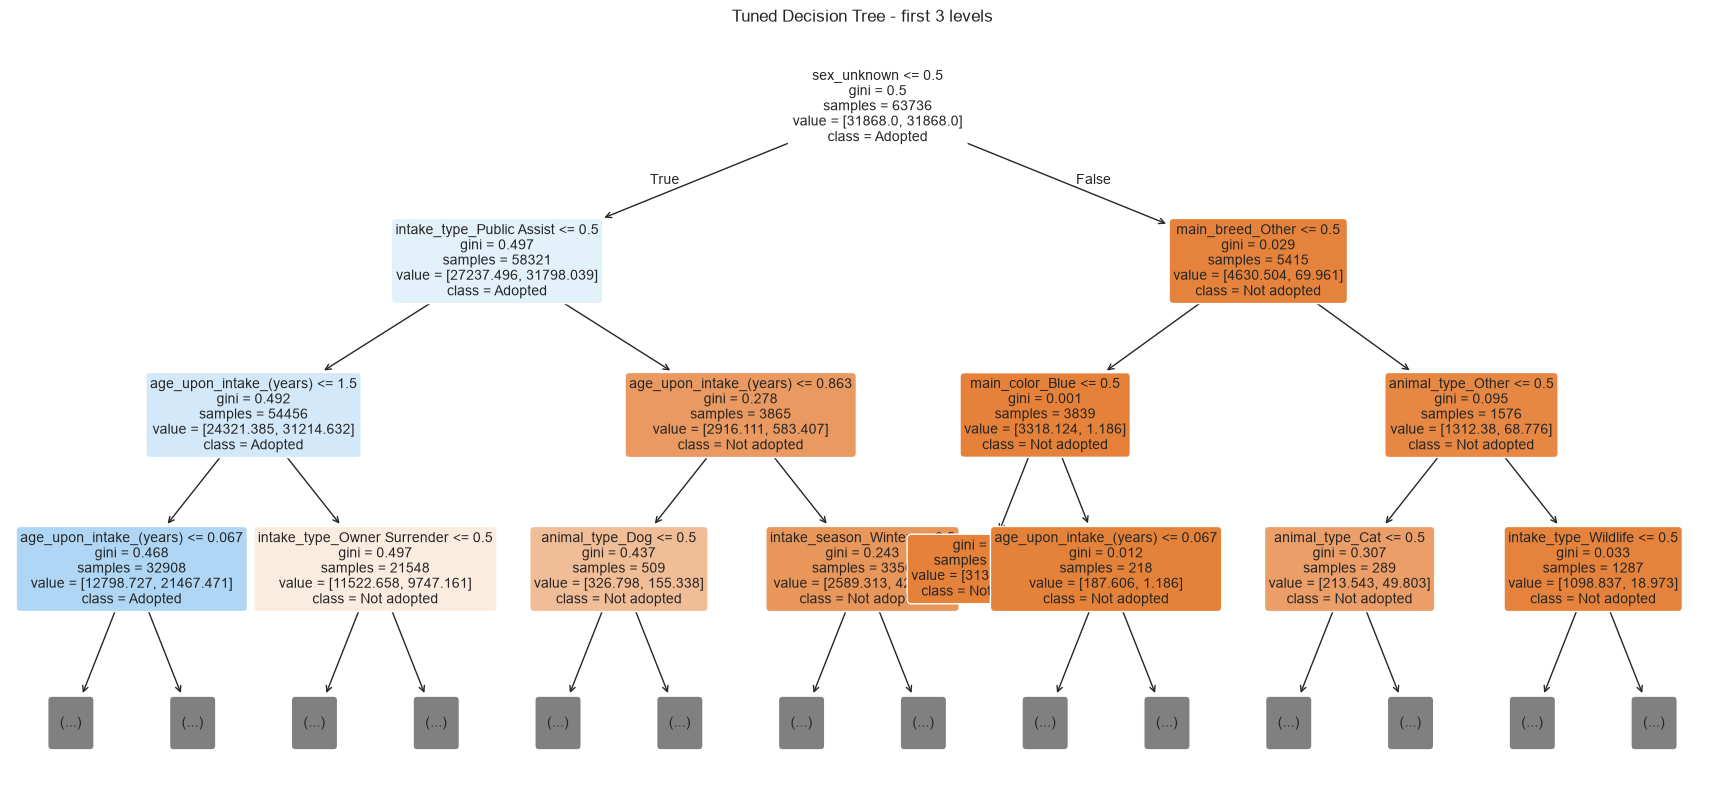

In [19]:
print("Tuned tree - train accuracy:", round(best_tree.score(X_train, y_train), 3))
print("Tuned tree - test accuracy: ", round(best_tree.score(X_test, y_test), 3))

plt.figure(figsize=(22, 10))
plot_tree(best_tree, max_depth=3, feature_names=X.columns,
          class_names=["Not adopted", "Adopted"], filled=True, rounded=True, fontsize=10)
plt.title("Tuned Decision Tree - first 3 levels")
plt.show()

## 5. Ensemble models

In [20]:
search_rf = RandomizedSearchCV(
    RandomForestClassifier(class_weight="balanced", random_state=42, n_jobs=-1),
    {"n_estimators": [100, 200, 300],
     "max_depth": [10, 15, 20, None],
     "min_samples_leaf": [1, 5, 10, 20]},
    n_iter=10, cv=3, scoring="f1", random_state=42, n_jobs=-1,
).fit(X_train, y_train)

search_gb = RandomizedSearchCV(
    HistGradientBoostingClassifier(class_weight="balanced", random_state=42),
    {"learning_rate": [0.03, 0.05, 0.1, 0.2],
     "max_iter": [100, 200, 300],
     "max_depth": [3, 5, 8, None]},
    n_iter=10, cv=3, scoring="f1", random_state=42, n_jobs=-1,
).fit(X_train, y_train)

print("Random Forest:", search_rf.best_params_, round(search_rf.best_score_, 3))
print("Gradient Boosting:", search_gb.best_params_, round(search_gb.best_score_, 3))

best_rf = search_rf.best_estimator_
best_gb = search_gb.best_estimator_

Random Forest: {'n_estimators': 100, 'min_samples_leaf': 1, 'max_depth': 15} 0.691
Gradient Boosting: {'max_iter': 200, 'max_depth': 8, 'learning_rate': 0.2} 0.689


## 6. Final model evaluation

In [21]:
final_table = results_table([
    evaluate_model("Baseline", baseline, X_test, y_test),
    evaluate_model("KNN", knn, X_test_scaled, y_test),
    evaluate_model("Logistic Regression (tuned)", best_lr, X_test_scaled, y_test),
    evaluate_model("Decision Tree (tuned)", best_tree, X_test, y_test),
    evaluate_model("Gradient Boosting (tuned)", best_gb, X_test, y_test),
    evaluate_model("Random Forest (tuned)", best_rf, X_test, y_test),
])
final_table

,model,accuracy,precision,recall,f1
0,Random Forest (tuned),0.703,0.615,0.795,0.693
1,Gradient Boosting (tuned),0.705,0.620,0.779,0.690
2,Decision Tree (tuned),0.703,0.619,0.773,0.687
3,Logistic Regression (tuned),0.665,0.577,0.773,0.661
4,KNN,0.669,0.608,0.603,0.606
5,Baseline,0.578,0.000,0.000,0.000


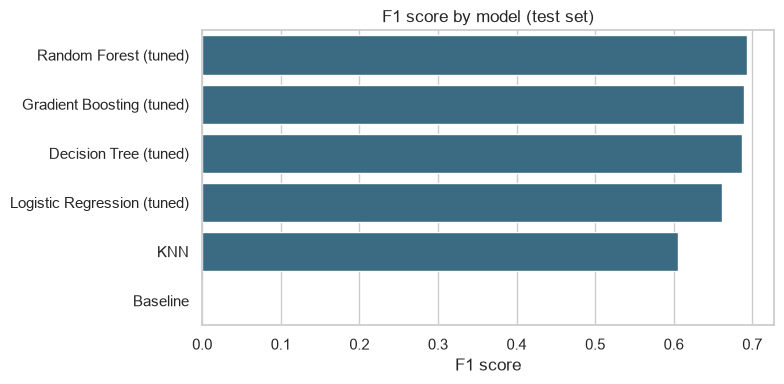

In [22]:
plt.figure(figsize=(8, 4))
sns.barplot(data=final_table, x="f1", y="model", color="#2F6F8F")
plt.title("F1 score by model (test set)")
plt.xlabel("F1 score")
plt.ylabel("")
plt.tight_layout()
plt.show()

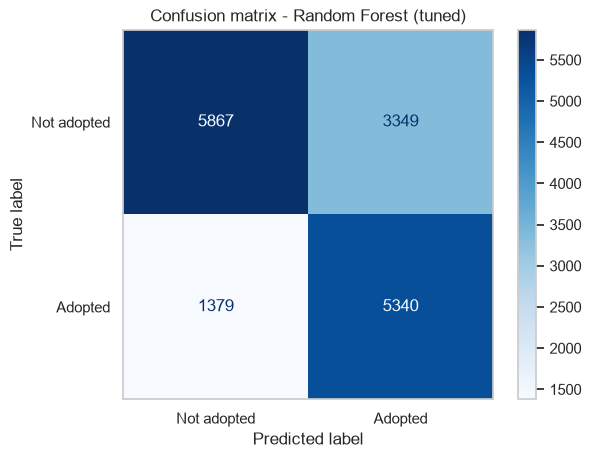

In [23]:
best_model = best_rf

ConfusionMatrixDisplay.from_estimator(
    best_model, X_test, y_test, display_labels=["Not adopted", "Adopted"], cmap="Blues"
)
plt.title("Confusion matrix - Random Forest (tuned)")
plt.grid(False)
plt.show()

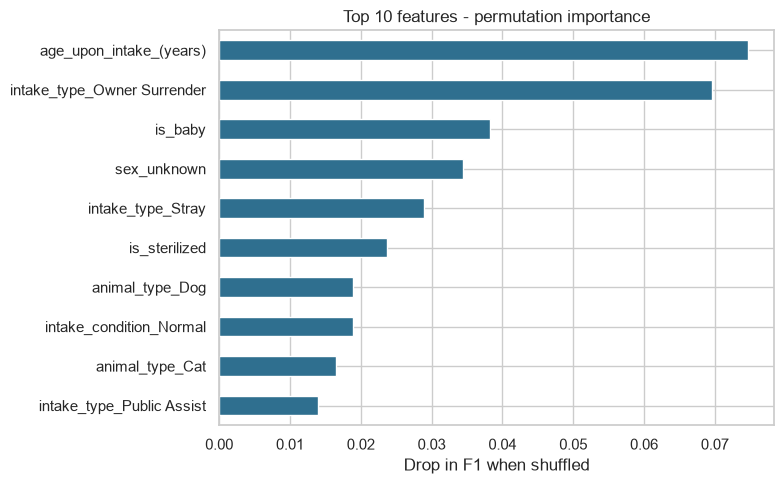

In [24]:
perm = permutation_importance(best_model, X_test, y_test, scoring="f1",
                              n_repeats=5, random_state=42, n_jobs=-1)
top10 = pd.Series(perm.importances_mean, index=X.columns).sort_values(ascending=False).head(10)

top10.sort_values().plot(kind="barh", figsize=(8, 5), color="#2F6F8F")
plt.title("Top 10 features - permutation importance")
plt.xlabel("Drop in F1 when shuffled")
plt.tight_layout()
plt.show()

In [25]:
import joblib
joblib.dump(best_model, "final_model.pkl")

['final_model.pkl']

## 7. Conclusions

- **Problem:** binary classification – predict at intake whether a shelter animal will be adopted (79,671 animals, 42% adopted).
- **Data leakage avoided:** only features available on the day of intake were used.
- **Feature engineering:** 2,155 breeds and 529 colors reduced to the top 10 + `Other`; new features such as `is_baby`, `is_mix` and `is_sterilized`. Babies (51% vs 36%) and mixed breeds (43% vs 27%) are adopted more often.
- **Metric:** F1 score, because the baseline (always "not adopted") reaches 58% accuracy while finding no adopted animals.
- **Tuning mattered most:** Grid Search with `class_weight="balanced"` raised the Decision Tree F1 from 0.60 to 0.69 and removed the overfitting. Ensembles added only a small improvement.
- **Best model:** tuned Random Forest – F1 0.69, recall 0.80 (it finds 8 in 10 adopted animals), accuracy 0.70.
- **Most important features:** age, being given up by the owner, being a baby, unknown sex (mostly wildlife) and being found as a stray.

**Real-world use:** any shelter with similar data could flag animals with a low adoption chance on day one and invest more in promoting them. A low score should mean more support, never less care.

**Limitations and next steps:** data from a single shelter (2013–2018), no photos or behaviour information. Next steps: more recent data, images of the animals and a simple tool for shelter staff.